# Funniest Outdoor — Cleaning, Audit Data Riil, & Generator Basket Sintetis v3 (Anti-Leakage & High-Uniqueness)

**Tim:** Nexa404 (`A26-CS144`) — Capstone Asah 2026  
**Mitra UMKM:** Funniest Outdoor (Surabaya Utara)  
**Status Notebook:** Versi 3 (v3) bersih, linier, bebas output tersimpan, bebas PII mentah, siap dijalankan top-to-bottom di Google Colab atau lokal.

### Ringkasan Peningkatan v3 (Menjawab Seluruh Review Kalibrasi & Anti-Leakage)
1. **Keunikan Basket Tinggi ($\ge 90\%$):** Campuran berbobot Tier 1 + Tier 2 (`TIER2_MIX_WEIGHT = 0.35`), *controlled noise* `8%`, variasi ukuran lebih luas, dan *rejection cap* duplikat (`cap = 1` untuk `individual`/`mixed`, `cap = 2` untuk `bundle`) → menghasilkan **98,8% kombinasi unik** (`individual` 100%, `mixed` 100%, `bundle` 88,5%, maks pengulangan 2×).
2. **Nol Basket Ukuran 1 (`min_size = 2`):** Seluruh basket memiliki minimal 2 SKU (termasuk `bundle` yang selalu memiliki $\ge 1$ add-on kontekstual), sehingga 100% basket berguna untuk melatih model relasi antar-item.
3. **Group Split 80/20 Anti-Leakage (`split = train / test`):** Pemisahan train/test dilakukan per kombinasi unik (`combo_key`) secara terstratifikasi per skenario → menjamin **0,0% exact-duplicate leakage**.
4. **Benchmark Jujur Tanpa Memorisasi:** Menyertakan uji *Random Leave-One-Out* (`HitRate@5` & `NDCG@5`) membandingkan **Baseline Popularitas** vs **Cosine Co-occurrence** di atas test set bebas kebocoran.
5. **Ekspor Siap Pipeline ML:** Selain Excel multi-sheet (`Synthetic_Basket_Dataset_4000_v3.xlsx`), mengekspor langsung file long-format **`synthetic_order_details_v3.csv`** (sudah memuat kolom `split`, `quantity`, `unit_price`, `subtotal`, tanggal/durasi, `data_source`) tanpa perlu `ast.literal_eval`.
6. **Seluruh Perbaikan v2 Tetap Dipertahankan:** Anonimisasi PII (`orders_clean`), rekonsiliasi `Uang Masuk`, tabel `daily_rates`, mapping 73 entri `Produk Terlaris` (termasuk 4 SKU bermasalah), relasi katalog + `bundle_items`, `conflict_groups` lengkap (0 pelanggaran), kalibrasi bobot pangkat + prior kecil `0.5`, serta tanggal/durasi/quantity/harga katalog.


## 1. Setup Library & Load Data Sumber


In [1]:
import glob
import hashlib
import os
import re
from collections import Counter, defaultdict
from datetime import date, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

RANDOM_SEED = 2026
PII_SALT = "funniest_outdoor_asah2026_v3"
print("Library siap. Seed:", RANDOM_SEED)


Library siap. Seed: 2026


In [2]:
csv_candidates = sorted(glob.glob("*Katalog*.csv"))
xlsx_candidates = sorted(glob.glob("*SewaScale*.xlsx"))

if not csv_candidates or not xlsx_candidates:
    try:
        from google.colab import files
        print("Upload file CSV Katalog & Excel Laporan SewaScale:")
        files.upload()
        csv_candidates = sorted(glob.glob("*Katalog*.csv"))
        xlsx_candidates = sorted(glob.glob("*SewaScale*.xlsx"))
    except ImportError:
        pass

assert csv_candidates, "File CSV Katalog tidak ditemukan!"
assert xlsx_candidates, "File Excel Laporan SewaScale tidak ditemukan!"

CATALOG_CSV_PATH = csv_candidates[0]
SEWASCALE_XLSX_PATH = xlsx_candidates[0]
print("Catalog CSV   :", CATALOG_CSV_PATH)
print("SewaScale XLSX:", SEWASCALE_XLSX_PATH)


Catalog CSV   : Katalog Produk & Harga Sewa Perlengkapan Outdoor - Katalog Sewa.csv
SewaScale XLSX: Laporan_SewaScale_01_09_2026_–_30_09_2026_2026-10-23 (1).xlsx


## 2. Cleaning Katalog (78 SKU), `daily_rates`, & `bundle_items`


In [3]:
df_catalog_raw = pd.read_csv(CATALOG_CSV_PATH)
new_columns = df_catalog_raw.iloc[6, 1:12].tolist()

df_catalog_clean = df_catalog_raw.iloc[7:, 1:12].copy()
df_catalog_clean.columns = new_columns
df_catalog_clean = df_catalog_clean[pd.to_numeric(df_catalog_clean["No"], errors="coerce").notna()].copy()
df_catalog_clean["No"] = df_catalog_clean["No"].astype(int)
df_catalog_clean = df_catalog_clean.reset_index(drop=True)

for col in ["Kategori", "Nama Produk / Paket", "Rincian Isi Paket", "Catatan Produk", "Ref. Gambar"]:
    df_catalog_clean[col] = df_catalog_clean[col].fillna("").astype(str).str.strip()

price_columns = ["Sewa 1 Hari", "Sewa 2 Hari", "Sewa 3 Hari", "Sewa 4 Hari", "Biaya +Hari"]
for col in price_columns:
    cleaned = df_catalog_clean[col].astype(str).str.replace(r"[^\d]", "", regex=True).replace("", np.nan)
    df_catalog_clean[col] = pd.to_numeric(cleaned, errors="coerce").astype("Int64")

df_catalog_clean["product_id"] = df_catalog_clean["No"].apply(lambda x: f"P{x:03d}")
df_catalog_clean["product_name_clean"] = df_catalog_clean["Nama Produk / Paket"]
df_catalog_clean["nama_normalized"] = (
    df_catalog_clean["product_name_clean"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
)

def classify_product(category):
    if category == "Produk Dijual":
        return "sold_product"
    if category.startswith("Paket"):
        return "bundle"
    return "individual_rental"

df_catalog_clean["product_type"] = df_catalog_clean["Kategori"].apply(classify_product)
assert len(df_catalog_clean) == 78 and df_catalog_clean["product_id"].is_unique

catalog_lookup = df_catalog_clean.set_index("product_id").to_dict(orient="index")

def get_unit_price(product_id, duration_days):
    c = catalog_lookup[product_id]
    if c["product_type"] == "sold_product":
        return int(c["Sewa 1 Hari"]), "sold_unit_price"
    if product_id == "P052":
        return int(c["Sewa 1 Hari"]), "flat_per_trip"
    d = int(duration_days)
    if d <= 1:
        return int(c["Sewa 1 Hari"]), "catalog_tier_1d"
    if d == 2:
        return int(c["Sewa 2 Hari"]), "catalog_tier_2d"
    if d == 3:
        return int(c["Sewa 3 Hari"]), "catalog_tier_3d"
    if d == 4:
        return int(c["Sewa 4 Hari"]), "catalog_tier_4d"
    if pd.notna(c["Biaya +Hari"]):
        return int(c["Sewa 4 Hari"]) + (d - 4) * int(c["Biaya +Hari"]), "catalog_extra_day"
    inferred_extra = int(c["Sewa 4 Hari"]) - int(c["Sewa 3 Hari"])
    return int(c["Sewa 4 Hari"]) + (d - 4) * inferred_extra, "inferred_bundle_extra_day"

daily_rates_rows = []
for pid in sorted(catalog_lookup):
    c = catalog_lookup[pid]
    if c["product_type"] == "sold_product":
        daily_rates_rows.append({"product_id": pid, "product_name": c["product_name_clean"], "product_type": c["product_type"], "duration_days": pd.NA, "unit_price": int(c["Sewa 1 Hari"]), "pricing_rule": "sold_unit_price"})
    else:
        for d in range(1, 9):
            pr, rule = get_unit_price(pid, d)
            daily_rates_rows.append({"product_id": pid, "product_name": c["product_name_clean"], "product_type": c["product_type"], "duration_days": d, "unit_price": pr, "pricing_rule": rule})
df_daily_rates = pd.DataFrame(daily_rates_rows)
print("Katalog bersih:", df_catalog_clean.shape, "| df_daily_rates:", df_daily_rates.shape)


Katalog bersih: (78, 15) | df_daily_rates: (547, 6)


In [4]:
bundle_items_data = [
    ["P001", "Sepatu", 1], ["P001", "Hydropack", 1], ["P001", "Trekking Pole", 1], ["P001", "Headlamp", 1], ["P001", "Baterai", 3],
    ["P002", "Carrier", 1], ["P002", "Sepatu", 1], ["P002", "Sleeping Bag", 1], ["P002", "Trekking Pole", 1], ["P002", "Headlamp", 1], ["P002", "Matras", 1], ["P002", "Baterai", 3],
    ["P003", "Flysheet", 1],
    ["P004", "Tenda 2P", 1], ["P004", "Sleeping Bag", 2], ["P004", "Matras", 2], ["P004", "Nesting", 1], ["P004", "Kompor", 1], ["P004", "Gas", 1], ["P004", "Lampu Tenda", 1],
    ["P005", "Tenda 3-4P", 1], ["P005", "Sleeping Bag", 3], ["P005", "Matras", 3], ["P005", "Nesting", 1], ["P005", "Kompor", 1], ["P005", "Gas", 1], ["P005", "Lampu Tenda", 1], ["P005", "Baterai", 3],
    ["P006", "Tenda 4-5P", 1], ["P006", "Sleeping Bag", 4], ["P006", "Matras", 4], ["P006", "Nesting", 1], ["P006", "Kompor", 1], ["P006", "Gas", 1], ["P006", "Lampu Tenda", 1], ["P006", "Baterai", 3],
    ["P007", "Tenda 6P", 1], ["P007", "Sleeping Bag", 6], ["P007", "Matras", 5], ["P007", "Nesting", 1], ["P007", "Kompor", 1], ["P007", "Gas", 1], ["P007", "Lampu Tenda", 1], ["P007", "Baterai", 3],
    ["P008", "Kompor", 1], ["P008", "Grill Pan", 1], ["P008", "Capit Makanan", 1], ["P008", "Spatula", 1], ["P008", "Kuas", 1], ["P008", "Mangkok", 2], ["P008", "Sumpit", 2],
    ["P009", "Kompor", 1], ["P009", "Grill Pan", 1], ["P009", "Gas", 1], ["P009", "Capit Makanan", 1], ["P009", "Spatula", 1], ["P009", "Kuas", 1], ["P009", "Mangkok", 2], ["P009", "Sumpit", 2],
    ["P010", "Kompor", 1], ["P010", "Grill Pan", 1], ["P010", "Gas", 1], ["P010", "Tikar", 1], ["P010", "Capit Makanan", 1], ["P010", "Spatula", 1], ["P010", "Kuas", 1], ["P010", "Mangkok", 2], ["P010", "Sumpit", 2],
    ["P011", "Kursi Lipat", 2],
    ["P012", "Kursi Lipat", 2], ["P012", "Meja Lipat", 1],
    ["P013", "Kursi Lipat", 2], ["P013", "Meja Lipat", 1], ["P013", "Tripod", 1],
    ["P014", "Tenda 2P", 1], ["P014", "Kursi Lipat", 2], ["P014", "Meja Lipat", 1], ["P014", "Tripod", 1],
]
bundle_items = pd.DataFrame(bundle_items_data, columns=["bundle_id", "item_name", "quantity"])

bundle_component_to_product_ids = {
    "Baterai": ["P077"], "Capit Makanan": [], "Carrier": ["P021", "P022", "P023", "P024", "P025", "P026", "P027", "P028"],
    "Flysheet": ["P063"], "Gas": ["P052"], "Grill Pan": ["P051"], "Headlamp": ["P054"], "Hydropack": ["P029", "P030"],
    "Kompor": ["P045", "P046", "P047"], "Kuas": [], "Kursi Lipat": ["P059"], "Lampu Tenda": ["P057"], "Mangkok": [],
    "Matras": ["P042"], "Meja Lipat": ["P060"], "Nesting": ["P049"], "Sepatu": ["P035"], "Sleeping Bag": ["P034"],
    "Spatula": [], "Sumpit": [], "Tenda 2P": ["P015", "P016", "P017", "P018", "P019", "P020"],
    "Tenda 3-4P": ["P015", "P016", "P017", "P018", "P019", "P020"], "Tenda 4-5P": ["P015", "P016", "P017", "P018", "P019", "P020"],
    "Tenda 6P": ["P015", "P016", "P017", "P018", "P019", "P020"], "Tikar": ["P066"], "Trekking Pole": ["P037"], "Tripod": ["P065"],
}
assert set(bundle_items["item_name"].unique()) == set(bundle_component_to_product_ids.keys())
print(f"Bundle items valid: {len(bundle_items)} relasi pada {bundle_items['bundle_id'].nunique()} paket.")


Bundle items valid: 78 relasi pada 14 paket.


## 3. `orders_clean` (Anonimisasi PII) & Mapping Lengkap `Produk Terlaris`


In [5]:
df_orders_raw = pd.read_excel(SEWASCALE_XLSX_PATH, sheet_name="Semua Order")
df_uang_masuk_raw = pd.read_excel(SEWASCALE_XLSX_PATH, sheet_name="Uang Masuk")

def hash_customer_id(row):
    phone = re.sub(r"\D", "", str(row.get("Telepon", "") or ""))
    name = re.sub(r"\s+", " ", str(row.get("Pelanggan", "") or "").strip().lower())
    key = phone if phone else name
    return "CUST-" + hashlib.sha256(f"{PII_SALT}|{key}".encode("utf-8")).hexdigest()[:10].upper()

orders_clean = pd.DataFrame()
orders_clean["no_order"] = df_orders_raw["No. Order"].astype(str).str.strip()
dup_counts = orders_clean["no_order"].value_counts()
orders_clean["is_duplicate_order_no"] = orders_clean["no_order"].map(dup_counts) > 1
seq = orders_clean.groupby("no_order").cumcount() + 1
orders_clean["order_uid"] = np.where(orders_clean["is_duplicate_order_no"], orders_clean["no_order"] + "#" + seq.astype(str), orders_clean["no_order"])
orders_clean["customer_id"] = df_orders_raw.apply(hash_customer_id, axis=1)

for src_col, dst_col in [("Tanggal Mulai", "tanggal_mulai"), ("Est. Kembali", "est_kembali"), ("Tgl Kembali", "tgl_kembali"), ("Tgl Buat", "tgl_buat")]:
    orders_clean[dst_col] = pd.to_datetime(df_orders_raw[src_col].replace("-", np.nan), format="%d/%m/%Y", errors="coerce")

orders_clean["duration_days"] = (orders_clean["est_kembali"] - orders_clean["tanggal_mulai"]).dt.days
orders_clean["actual_duration_days"] = (orders_clean["tgl_kembali"] - orders_clean["tanggal_mulai"]).dt.days
orders_clean["lead_time_days"] = (orders_clean["tanggal_mulai"] - orders_clean["tgl_buat"]).dt.days
orders_clean["is_negative_lead_time"] = orders_clean["lead_time_days"] < 0
orders_clean["start_dayofweek"] = orders_clean["tanggal_mulai"].dt.day_name()
orders_clean["is_weekend_start"] = orders_clean["tanggal_mulai"].dt.weekday.isin([4, 5])
orders_clean["status"] = df_orders_raw["Status"].astype(str).str.strip().str.lower()
orders_clean["bayar"] = df_orders_raw["Bayar"].astype(str).str.strip().str.lower()
orders_clean["metode_clean"] = df_orders_raw["Metode"].apply(
    lambda v: "Cash" if str(v or "").strip().lower() in ("cash", "cash / tunai") else ("Transfer BCA" if ("bca" in str(v or "").strip().lower() or str(v or "").strip().lower() == "transfer") else ("QRIS" if "qris" in str(v or "").strip().lower() else "Unknown"))
)
orders_clean["sales_clean"] = df_orders_raw["Sales"].apply(lambda v: "Moch. Ismail" if "ismail" in str(v or "").strip().lower() else "Unassigned")
for src_col, dst_col in [("Biaya Sewa", "biaya_sewa"), ("Denda", "denda"), ("Dibayar", "dibayar"), ("Total", "total")]:
    orders_clean[dst_col] = pd.to_numeric(df_orders_raw[src_col], errors="coerce").fillna(0).astype(int)
orders_clean["has_note"] = df_orders_raw["Catatan"].fillna("").astype(str).str.strip().ne("")
del df_orders_raw

um_clean = df_uang_masuk_raw[df_uang_masuk_raw["Metode"].fillna("").astype(str).str.strip().str.upper().ne("TOTAL UANG MASUK") & df_uang_masuk_raw["No. Order"].notna()]
assert int(pd.to_numeric(um_clean["Jumlah Bayar"], errors="coerce").sum()) == 43517500

df_orders_returned = orders_clean[orders_clean["status"] == "returned"].copy()
assert len(orders_clean) == 466 and len(df_orders_returned) == 459 and int(df_orders_returned["total"].sum()) == 42153000

dur_dist_real = df_orders_returned["duration_days"].clip(lower=1).value_counts(normalize=True).sort_index()
lead_dist_real = df_orders_returned["lead_time_days"].clip(lower=0).value_counts(normalize=True).sort_index()
dow_dist_real = df_orders_returned["tanggal_mulai"].dt.weekday.value_counts(normalize=True).sort_index()
print(f"orders_clean siap (ZERO PII): {len(orders_clean)} baris, returned={len(df_orders_returned)}, Mean Total=Rp{df_orders_returned['total'].mean():,.0f}")


orders_clean siap (ZERO PII): 466 baris, returned=459, Mean Total=Rp91,837


C:\Users\- LENOVO -\AppData\Local\Temp\ipykernel_26520\766974460.py:26: Pandas4Warning: Series.dt.weekday is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  orders_clean["is_weekend_start"] = orders_clean["tanggal_mulai"].dt.weekday.isin([4, 5])
C:\Users\- LENOVO -\AppData\Local\Temp\ipykernel_26520\766974460.py:46: Pandas4Warning: Series.dt.weekday is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  dow_dist_real = df_orders_returned["tanggal_mulai"].dt.weekday.value_counts(normalize=True).sort_index()


In [6]:
df_pop_raw = pd.read_excel(SEWASCALE_XLSX_PATH, sheet_name="Produk Terlaris")
cat_name_to_id = dict(zip(df_catalog_clean["nama_normalized"], df_catalog_clean["product_id"]))

MANUAL_SKU_MAPPING = {
    "tenda 4-5p": [("P017", 1.0, "verified")], "carrier": [("P028", 1.0, "verified")], "nesting": [("P049", 1.0, "verified")],
    "meja": [("P060", 1.0, "verified")], "tenda 6p": [("P018", 1.0, "verified")], "carrier eiger ecosavior putih": [("P021", 1.0, "verified")],
    "paket 2 kursi": [("P012", 1.0, "verified")], "tenda 2p": [("P015", 1.0, "verified")], "paket 1 kursi": [("P011", 1.0, "verified")],
    "wajan grill": [("P051", 1.0, "verified")], "tempat telur": [("P050", 1.0, "verified")], "carrier phalanger": [("P023", 1.0, "verified")],
    "paket 3 kursi": [("P013", 1.0, "verified")], "arei sentani": [("P025", 1.0, "verified")], "carrier eiger ecosavior kuning": [("P022", 1.0, "verified")],
    "topi eiger": [("P038", 1.0, "needs_review")],
    "carrier monte sigma": [("P026", 0.5, "needs_review_variant_split"), ("P027", 0.5, "needs_review_variant_split")],
    "tenda big adventure 2p": [("P019", 0.6, "needs_review_variant_split"), ("P020", 0.4, "needs_review_variant_split")],
    "matras lipat": [("P042", 1.0, "needs_review")],
    "slayer": [(None, 1.0, "unmapped_not_in_catalog")],
}

mapped_records = []
for _, row in df_pop_raw.iterrows():
    raw_name = str(row["Nama Produk"]).strip()
    norm = re.sub(r"\s+", " ", re.sub(r"\s*\(copy\)\s*$", "", raw_name, flags=re.I)).strip().lower()
    qty, days, rev = float(row["Qty Disewa"]), float(row["Hari Disewa"]), float(row["Total Revenue"])
    if norm in cat_name_to_id:
        mapped_records.append({"raw_name": raw_name, "product_id": cat_name_to_id[norm], "mapping_status": "exact_match", "qty_disewa": qty, "hari_disewa": days, "total_revenue": rev})
    else:
        for pid, frac, status in MANUAL_SKU_MAPPING[norm]:
            mapped_records.append({"raw_name": raw_name, "product_id": pid, "mapping_status": status, "qty_disewa": qty * frac, "hari_disewa": days * frac, "total_revenue": rev * frac})

df_pop_mapped = pd.DataFrame(mapped_records)
df_popularity_sku = (
    df_pop_mapped[df_pop_mapped["product_id"].notna()]
    .groupby("product_id", as_index=False)
    .agg(qty_disewa=("qty_disewa", "sum"), hari_disewa=("hari_disewa", "sum"), total_revenue=("total_revenue", "sum"))
)
real_qty = df_popularity_sku.set_index("product_id")["qty_disewa"].to_dict()
print(f"SKU terpetakan: {len(df_popularity_sku)}/78 | Qty: {df_popularity_sku['qty_disewa'].sum():,.0f}/{df_pop_raw['Qty Disewa'].sum():,.0f}")


SKU terpetakan: 70/78 | Qty: 3,253/3,287


## 3B. Exploratory Data Analysis (EDA) Bisnis & Temuan Menarik Data Riil (Sep 2026)

Bagian ini menjawab **4 pertanyaan bisnis utama** Funniest Outdoor menggunakan data riil teranonimisasi (`orders_clean` & `df_popularity_sku`):
1. **Pola Permintaan & Operasional:** Kapan puncak permintaan sewa terjadi (hari mulai sewa, durasi sewa, dan *lead time* booking)?
2. **Volume Driver vs Revenue Driver:** Produk apa yang paling banyak unitnya vs paling besar menyumbang omzet?
3. **Kontribusi Tipe Produk & Paket Bundle:** Seberapa besar kontribusi rental individual, produk dijual, dan paket bundle — serta paket mana yang paling diminati?
4. **Profil Nilai Transaksi & Metode Bayar:** Bagaimana sebaran nominal belanja pelanggan dan preferensi pembayaran?


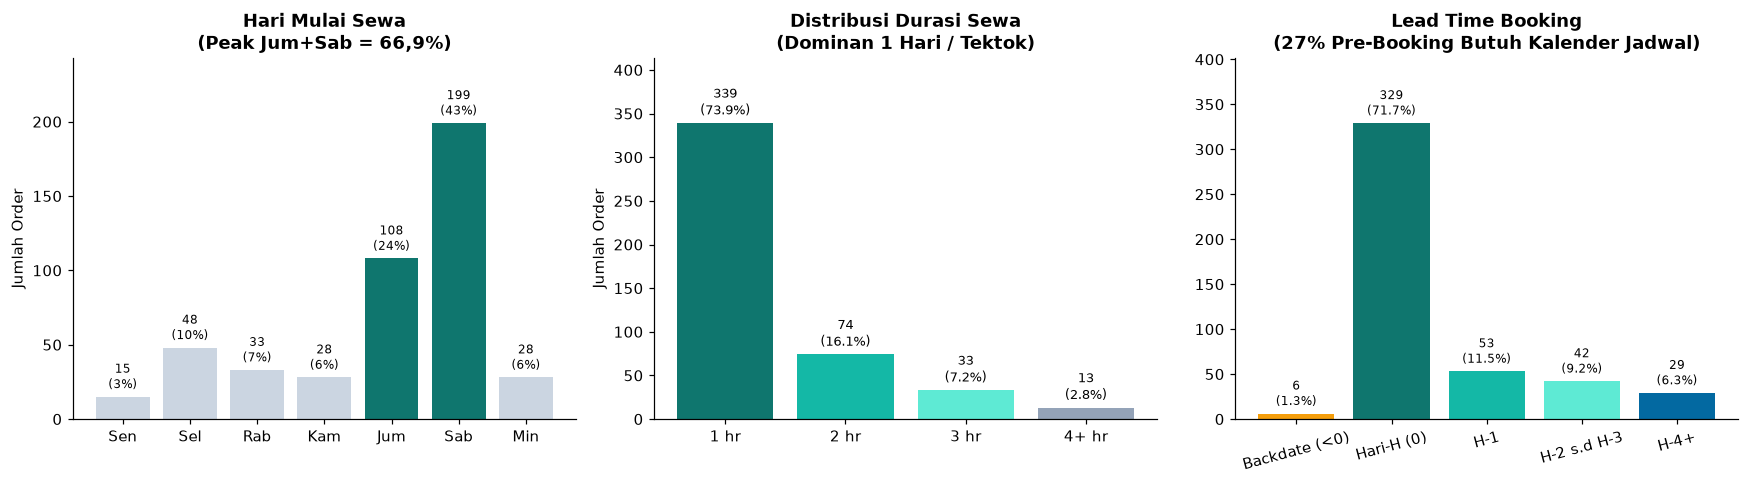

In [7]:
# EDA 1: Pola Permintaan — Hari Mulai Sewa, Durasi Sewa, & Lead Time Booking (Data Riil Returned, n=459)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Panel A: Hari Mulai Sewa (Senin-Minggu)
dow_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dow_labels = ["Sen", "Sel", "Rab", "Kam", "Jum", "Sab", "Min"]
dow_counts = df_orders_returned["start_dayofweek"].value_counts().reindex(dow_order, fill_value=0)
colors_dow = ["#CBD5E1" if d not in ("Friday", "Saturday") else "#0F766E" for d in dow_order]
bars = axes[0].bar(dow_labels, dow_counts.values, color=colors_dow, edgecolor="none")
for b, val in zip(bars, dow_counts.values):
    axes[0].text(b.get_x() + b.get_width()/2, val + 3, f"{val}\n({100*val/len(df_orders_returned):.0f}%)", ha="center", va="bottom", fontsize=8)
axes[0].set_title("Hari Mulai Sewa\n(Peak Jum+Sab = 66,9%)", fontweight="bold")
axes[0].set_ylabel("Jumlah Order")
axes[0].set_ylim(0, dow_counts.max() * 1.22)

# Panel B: Durasi Sewa (hari)
dur_vc = df_orders_returned["duration_days"].clip(lower=1).value_counts().sort_index()
dur_plot = pd.Series({
    "1 hr": dur_vc.get(1, 0),
    "2 hr": dur_vc.get(2, 0),
    "3 hr": dur_vc.get(3, 0),
    "4+ hr": dur_vc[dur_vc.index >= 4].sum(),
})
bars_d = axes[1].bar(dur_plot.index, dur_plot.values, color=["#0F766E", "#14B8A6", "#5EEAD4", "#94A3B8"])
for b, val in zip(bars_d, dur_plot.values):
    axes[1].text(b.get_x() + b.get_width()/2, val + 5, f"{val}\n({100*val/len(df_orders_returned):.1f}%)", ha="center", va="bottom", fontsize=8.5)
axes[1].set_title("Distribusi Durasi Sewa\n(Dominan 1 Hari / Tektok)", fontweight="bold")
axes[1].set_ylabel("Jumlah Order")
axes[1].set_ylim(0, dur_plot.max() * 1.22)

# Panel C: Lead Time Booking
lt = df_orders_returned["lead_time_days"]
lt_buckets = pd.Series({
    "Backdate (<0)": (lt < 0).sum(),
    "Hari-H (0)": (lt == 0).sum(),
    "H-1": (lt == 1).sum(),
    "H-2 s.d H-3": lt.isin([2, 3]).sum(),
    "H-4+": (lt >= 4).sum(),
})
bars_l = axes[2].bar(lt_buckets.index, lt_buckets.values, color=["#F59E0B", "#0F766E", "#14B8A6", "#5EEAD4", "#0369A1"])
for b, val in zip(bars_l, lt_buckets.values):
    axes[2].text(b.get_x() + b.get_width()/2, val + 5, f"{val}\n({100*val/len(df_orders_returned):.1f}%)", ha="center", va="bottom", fontsize=8)
axes[2].set_title("Lead Time Booking\n(27% Pre-Booking Butuh Kalender Jadwal)", fontweight="bold")
axes[2].tick_params(axis="x", rotation=15)
axes[2].set_ylim(0, lt_buckets.max() * 1.22)

plt.tight_layout()
plt.show()


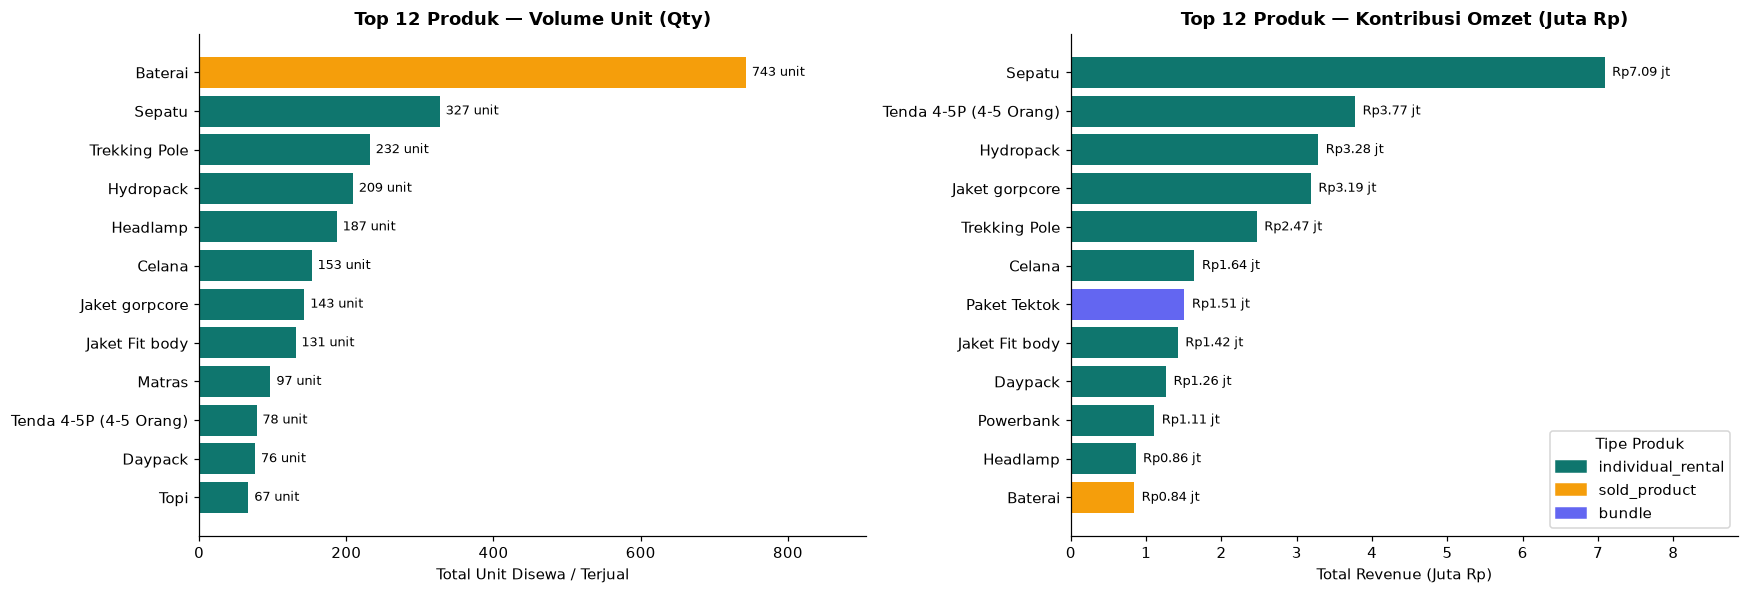

Temuan Katalog — Efek 3x Baterai AAA:
  Total unit Headlamp+Senter+Lampu Tenda = 253 unit -> estimasi kebutuhan 3x = 759 baterai
  Penjualan riil Baterai (P077)          = 743 unit (97.9% rasio terhadap kebutuhan 3x!)


In [8]:
# EDA 2: Volume Driver (Qty) vs Revenue Driver (Rp) — Top 12 SKU Riil
df_pop_named = df_popularity_sku.merge(
    df_catalog_clean[["product_id", "product_name_clean", "product_type"]], on="product_id", how="left"
)
top_qty = df_pop_named.sort_values("qty_disewa", ascending=False).head(12).iloc[::-1]
top_rev = df_pop_named.sort_values("total_revenue", ascending=False).head(12).iloc[::-1]

type_color = {"individual_rental": "#0F766E", "sold_product": "#F59E0B", "bundle": "#6366F1"}

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

axes[0].barh(top_qty["product_name_clean"], top_qty["qty_disewa"], color=[type_color[t] for t in top_qty["product_type"]])
for idx_v, (_, row) in enumerate(top_qty.iterrows()):
    axes[0].text(row["qty_disewa"] + 8, idx_v, f"{int(row['qty_disewa'])} unit", va="center", fontsize=8.5)
axes[0].set_title("Top 12 Produk — Volume Unit (Qty)", fontweight="bold")
axes[0].set_xlabel("Total Unit Disewa / Terjual")
axes[0].set_xlim(0, top_qty["qty_disewa"].max() * 1.22)

axes[1].barh(top_rev["product_name_clean"], top_rev["total_revenue"] / 1e6, color=[type_color[t] for t in top_rev["product_type"]])
for idx_v, (_, row) in enumerate(top_rev.iterrows()):
    axes[1].text(row["total_revenue"]/1e6 + 0.1, idx_v, f"Rp{row['total_revenue']/1e6:.2f} jt", va="center", fontsize=8.5)
axes[1].set_title("Top 12 Produk — Kontribusi Omzet (Juta Rp)", fontweight="bold")
axes[1].set_xlabel("Total Revenue (Juta Rp)")
axes[1].set_xlim(0, (top_rev["total_revenue"].max() / 1e6) * 1.25)

from matplotlib.patches import Patch
legend_handles = [Patch(color=c, label=k) for k, c in type_color.items()]
axes[1].legend(handles=legend_handles, title="Tipe Produk", loc="lower right")
plt.tight_layout()
plt.show()

# Temuan menarik: Efek 3x Baterai AAA terhadap lampu tanpa baterai
lamp_units_real = df_popularity_sku[df_popularity_sku["product_id"].isin(["P053", "P054", "P057"])]["qty_disewa"].sum()
bat_units_real = df_popularity_sku[df_popularity_sku["product_id"] == "P077"]["qty_disewa"].sum()
print(f"Temuan Katalog — Efek 3x Baterai AAA:")
print(f"  Total unit Headlamp+Senter+Lampu Tenda = {int(lamp_units_real)} unit -> estimasi kebutuhan 3x = {int(lamp_units_real*3)} baterai")
print(f"  Penjualan riil Baterai (P077)          = {int(bat_units_real)} unit ({100*bat_units_real/(lamp_units_real*3):.1f}% rasio terhadap kebutuhan 3x!)")


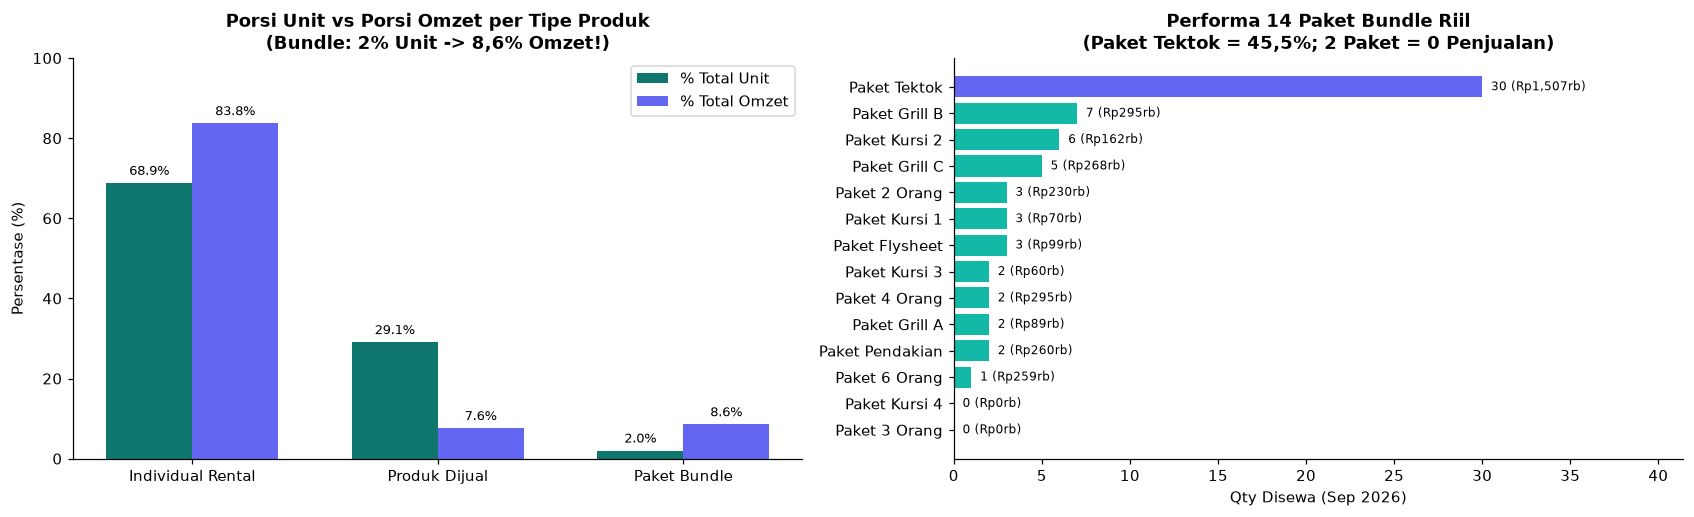

In [9]:
# EDA 3: Kontribusi Tipe Produk (Unit vs Omzet) & Performa 14 Paket Bundle
type_agg = df_pop_named.groupby("product_type", as_index=False).agg(qty=("qty_disewa", "sum"), rev=("total_revenue", "sum"))
type_agg["qty_pct"] = 100 * type_agg["qty"] / type_agg["qty"].sum()
type_agg["rev_pct"] = 100 * type_agg["rev"] / type_agg["rev"].sum()
type_agg = type_agg.set_index("product_type").reindex(["individual_rental", "sold_product", "bundle"]).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(15.5, 4.8))

# Panel A: % Unit vs % Omzet per Tipe Produk
x = np.arange(len(type_agg))
w = 0.35
b1 = axes[0].bar(x - w/2, type_agg["qty_pct"], width=w, label="% Total Unit", color="#0F766E")
b2 = axes[0].bar(x + w/2, type_agg["rev_pct"], width=w, label="% Total Omzet", color="#6366F1")
for b in list(b1) + list(b2):
    h = b.get_height()
    axes[0].text(b.get_x() + b.get_width()/2, h + 1.2, f"{h:.1f}%", ha="center", va="bottom", fontsize=8.5)
axes[0].set_xticks(x)
axes[0].set_xticklabels(["Individual Rental", "Produk Dijual", "Paket Bundle"])
axes[0].set_ylabel("Persentase (%)")
axes[0].set_ylim(0, 100)
axes[0].set_title("Porsi Unit vs Porsi Omzet per Tipe Produk\n(Bundle: 2% Unit -> 8,6% Omzet!)", fontweight="bold")
axes[0].legend()

# Panel B: Penjualan Riil 14 Paket Bundle
df_bun_perf = df_catalog_clean[df_catalog_clean["product_type"] == "bundle"][["product_id", "product_name_clean"]].merge(
    df_popularity_sku[["product_id", "qty_disewa", "total_revenue"]], on="product_id", how="left"
).fillna(0).sort_values("qty_disewa", ascending=True)
colors_b = ["#EF4444" if q == 0 else ("#6366F1" if pid == "P001" else "#14B8A6") for pid, q in zip(df_bun_perf["product_id"], df_bun_perf["qty_disewa"])]
axes[1].barh(df_bun_perf["product_name_clean"], df_bun_perf["qty_disewa"], color=colors_b)
for idx_v, (_, row) in enumerate(df_bun_perf.iterrows()):
    axes[1].text(row["qty_disewa"] + 0.5, idx_v, f"{int(row['qty_disewa'])} (Rp{row['total_revenue']/1e3:,.0f}rb)", va="center", fontsize=8)
axes[1].set_title("Performa 14 Paket Bundle Riil\n(Paket Tektok = 45,5%; 2 Paket = 0 Penjualan)", fontweight="bold")
axes[1].set_xlabel("Qty Disewa (Sep 2026)")
axes[1].set_xlim(0, df_bun_perf["qty_disewa"].max() * 1.38)

plt.tight_layout()
plt.show()


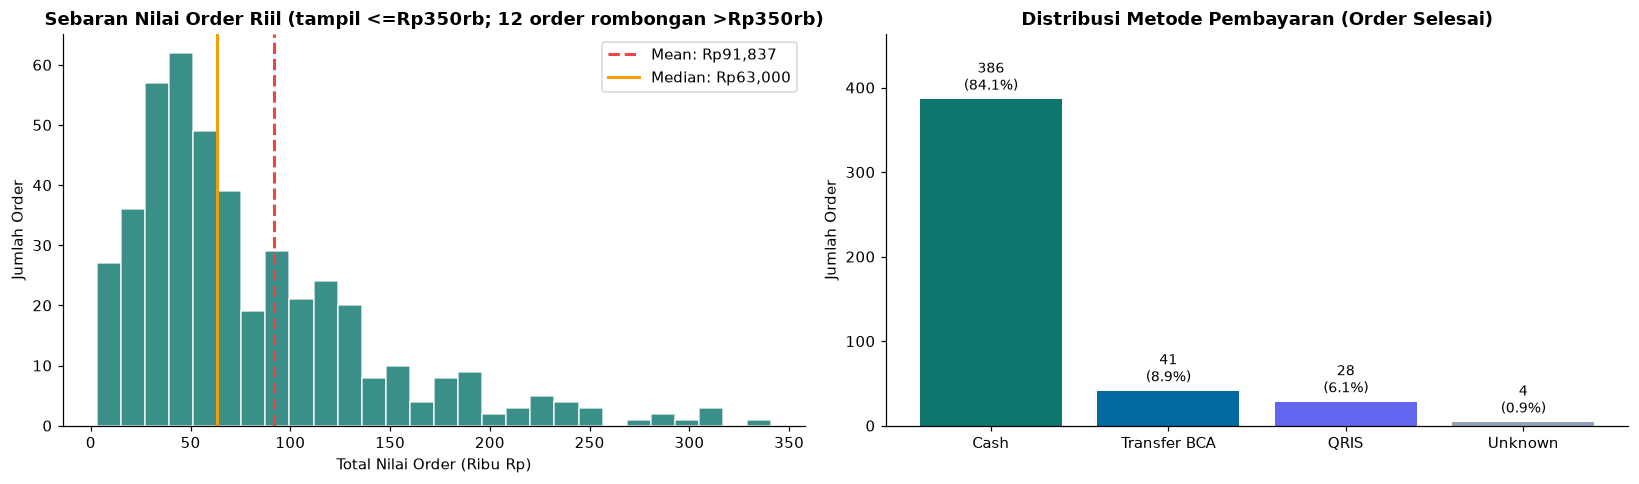

In [10]:
# EDA 4: Distribusi Nilai Transaksi (Basket Value) & Metode Pembayaran (Data Riil Returned)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

# Panel A: Histogram Nilai Transaksi (tampilkan <= Rp350rb agar pola utama terbaca jelas)
totals = df_orders_returned["total"]
totals_clip = totals[totals <= 350000] / 1e3
axes[0].hist(totals_clip, bins=28, color="#0F766E", alpha=0.82, edgecolor="white")
axes[0].axvline(totals.mean() / 1e3, color="#EF4444", linestyle="--", linewidth=2, label=f"Mean: Rp{totals.mean():,.0f}")
axes[0].axvline(totals.median() / 1e3, color="#F59E0B", linestyle="-", linewidth=2, label=f"Median: Rp{totals.median():,.0f}")
axes[0].set_title(f"Sebaran Nilai Order Riil (tampil <=Rp350rb; {(totals > 350000).sum()} order rombongan >Rp350rb)", fontweight="bold")
axes[0].set_xlabel("Total Nilai Order (Ribu Rp)")
axes[0].set_ylabel("Jumlah Order")
axes[0].legend()

# Panel B: Metode Pembayaran
met_vc = df_orders_returned["metode_clean"].value_counts()
bars_m = axes[1].bar(met_vc.index, met_vc.values, color=["#0F766E", "#0369A1", "#6366F1", "#94A3B8"][:len(met_vc)])
for b, val in zip(bars_m, met_vc.values):
    axes[1].text(b.get_x() + b.get_width()/2, val + 6, f"{val}\n({100*val/len(df_orders_returned):.1f}%)", ha="center", va="bottom", fontsize=9)
axes[1].set_title("Distribusi Metode Pembayaran (Order Selesai)", fontweight="bold")
axes[1].set_ylabel("Jumlah Order")
axes[1].set_ylim(0, met_vc.max() * 1.2)

plt.tight_layout()
plt.show()


### Ringkasan Temuan Bisnis Utama dari EDA Data Riil
1. **Lonjakan Akhir Pekan & Pola Tektok:** **66,9%** sewa dimulai Jumat–Sabtu dan **73,9%** berdurasi 1 hari, sementara **27%** pelanggan memesan di muka (`H-1` s.d. `H-17`). Ini memvalidasi urgensi fitur **kalender *schedule-aware*** agar pemesanan akhir pekan berikutnya tidak terblokir stok yang sedang dipakai hari ini.
2. **Volume Driver $
eq$ Revenue Driver:** `Baterai` mendominasi volume (743 unit), tetapi omzet terbesar datang dari `Sepatu` (Rp7,09 jt), `Tenda 4-5P` (Rp3,77 jt), `Hydropack` (Rp3,28 jt), dan `Jaket gorpcore` (Rp3,19 jt).
3. **Efek 3× Baterai AAA (~98% Attachment):** Penjualan `Baterai` (743 unit) hampir persis $3	imes$ total unit lampu tanpa baterai (253 unit $	imes 3 = 759$). Ini menjadi sinyal rekomendasi pelengkap paling kuat di keranjang belanja.
4. **Daya Ungkit Paket Bundle:** Meski baru **2,0%** dari total unit, paket bundle menyumbang **8,6%** omzet dengan `Paket Tektok` mendominasi **45,5%** penjualan paket. Sebaliknya, `Paket 3 Orang` & `Paket Kursi 4` belum terjual (kandidat promosi/rekomendasi *upsell*).
5. **Kesenjangan Katalog:** `Slayer` terjual **34 unit** (Rp375rb, peringkat #20 terlaris) namun belum ada di katalog 78 produk — rekomendasi cepat untuk ditambahkan ke katalog web.


## 4. Relasi Katalog (`substitutes`, `complements`, `conditional`) & Add-on Kontekstual


In [11]:
TENTS = {"P015", "P016", "P017", "P018", "P019", "P020"}
STOVES = {"P045", "P046", "P047"}
CARRIERS_PREMIUM = {"P021", "P022", "P023", "P024", "P025", "P026", "P027"}
CARRIERS_ALL = CARRIERS_PREMIUM | {"P028"}
MAIN_BAGS = CARRIERS_ALL | {"P029", "P030"}
JACKETS = {"P036", "P039", "P044"}
PERSONAL_LIGHTS = {"P053", "P054"}
CAMP_LIGHTS = {"P055", "P056", "P057"}
MAT_SHEETS = {"P066", "P067"}
BATTERY_LAMPS = {"P053", "P054", "P056", "P057"}
PERSONAL_SCALABLE = {"P035", "P037", "P030", "P029", "P054", "P053", "P040", "P039", "P044", "P036", "P038", "P041", "P043", "P034", "P042", "P059"}
CONFLICT_GROUPS = [TENTS, STOVES, MAIN_BAGS, JACKETS, PERSONAL_LIGHTS, CAMP_LIGHTS, MAT_SHEETS]

def has_conflict(pid, selected_set):
    for grp in CONFLICT_GROUPS:
        if pid in grp and any(s in grp for s in selected_set):
            return True
    if pid == "P032" and any(s in CARRIERS_PREMIUM for s in selected_set):
        return True
    if pid in CARRIERS_PREMIUM and "P032" in selected_set:
        return True
    all_lights = PERSONAL_LIGHTS | CAMP_LIGHTS
    if pid in all_lights and sum(1 for s in selected_set if s in all_lights) >= 2:
        return True
    return False

COMPLEMENTS = {}
for tid in TENTS:
    COMPLEMENTS[tid] = ["P034", "P042", "P057", "P063", "P046", "P045", "P047", "P049", "P052", "P054", "P058", "P059", "P060", "P067", "P035", "P037", "P028", "P039", "P040", "P065"]
for cid in CARRIERS_ALL:
    base = ["P035", "P034", "P037", "P054", "P042", "P040", "P039", "P044", "P036", "P041", "P043", "P038", "P031", "P033", "P058", "P017", "P015", "P046", "P049", "P052", "P057"]
    if cid == "P028":
        base.append("P032")
    COMPLEMENTS[cid] = base
for bid in ["P029", "P030"]:
    COMPLEMENTS[bid] = ["P035", "P037", "P054", "P040", "P039", "P044", "P038", "P058", "P041", "P043", "P036", "P053", "P065", "P042", "P034", "P017"]
COMPLEMENTS.update({
    "P031": ["P028", "P021", "P024", "P026", "P035", "P037", "P054", "P039", "P040", "P058", "P034", "P042"],
    "P032": ["P028", "P029", "P035", "P037", "P054", "P039", "P040", "P034", "P042", "P058"],
    "P033": ["P028", "P029", "P030", "P035", "P039", "P040", "P058", "P054", "P037"],
    "P035": ["P037", "P030", "P029", "P054", "P040", "P039", "P044", "P038", "P058", "P042", "P034", "P028", "P041", "P043", "P036", "P017", "P053", "P065"],
    "P037": ["P035", "P030", "P029", "P054", "P040", "P039", "P044", "P038", "P058", "P042", "P034", "P028", "P041", "P043", "P036", "P017", "P053", "P065"],
    "P040": ["P035", "P037", "P030", "P029", "P039", "P044", "P036", "P054", "P038", "P041", "P043", "P058", "P028", "P042", "P034", "P065"],
    "P039": ["P035", "P037", "P030", "P029", "P040", "P054", "P038", "P041", "P043", "P058", "P042", "P034", "P028", "P017", "P065"],
    "P044": ["P035", "P037", "P030", "P029", "P040", "P054", "P038", "P041", "P043", "P058", "P042", "P034", "P065"],
    "P036": ["P035", "P037", "P028", "P030", "P040", "P054", "P041", "P043", "P034", "P042", "P017", "P058", "P038"],
    "P038": ["P035", "P037", "P030", "P029", "P040", "P039", "P044", "P054", "P058", "P043", "P065", "P042"],
    "P041": ["P035", "P037", "P039", "P044", "P036", "P040", "P030", "P028", "P054", "P043", "P034", "P042", "P058"],
    "P043": ["P035", "P037", "P039", "P044", "P036", "P040", "P054", "P038", "P041", "P030", "P028", "P058", "P042"],
    "P034": ["P042", "P017", "P015", "P018", "P019", "P057", "P054", "P063", "P028", "P035", "P046", "P049", "P052", "P039", "P036", "P058", "P037"],
    "P042": ["P034", "P017", "P015", "P018", "P019", "P057", "P054", "P063", "P028", "P035", "P037", "P030", "P046", "P049", "P052", "P058", "P039"],
    "P049": ["P046", "P045", "P047", "P052", "P017", "P015", "P018", "P034", "P042", "P057", "P048", "P050", "P062", "P054", "P058"],
    "P052": ["P046", "P045", "P047", "P049", "P051", "P017", "P015", "P018", "P034", "P042", "P057", "P054", "P059", "P060"],
    "P051": ["P045", "P047", "P046", "P052", "P048", "P059", "P060", "P066", "P057", "P063", "P065"],
    "P048": ["P046", "P045", "P049", "P052", "P051", "P017", "P054", "P062", "P034", "P042"],
    "P050": ["P046", "P049", "P052", "P017", "P034", "P042", "P048", "P057"],
    "P054": ["P035", "P037", "P030", "P029", "P040", "P039", "P044", "P058", "P038", "P042", "P034", "P017", "P028", "P057", "P041", "P043"],
    "P053": ["P035", "P037", "P030", "P029", "P058", "P042", "P034", "P017", "P057", "P040", "P039", "P038"],
    "P057": ["P017", "P015", "P018", "P034", "P042", "P063", "P046", "P049", "P052", "P054", "P058", "P059", "P060", "P035"],
    "P055": ["P017", "P018", "P063", "P059", "P060", "P066", "P045", "P052"],
    "P056": ["P017", "P015", "P063", "P059", "P060", "P065", "P061", "P066", "P058"],
    "P058": ["P035", "P037", "P030", "P029", "P054", "P040", "P039", "P044", "P017", "P034", "P042", "P065", "P038", "P028"],
    "P059": ["P060", "P065", "P066", "P017", "P015", "P063", "P057", "P045", "P051", "P052", "P061", "P058"],
    "P060": ["P059", "P065", "P066", "P017", "P015", "P063", "P057", "P045", "P051", "P052", "P058"],
    "P061": ["P063", "P059", "P060", "P066", "P017", "P034", "P042", "P057", "P058"],
    "P062": ["P046", "P045", "P049", "P052", "P017", "P034", "P042", "P057", "P059"],
    "P063": ["P017", "P015", "P018", "P034", "P042", "P057", "P059", "P060", "P046", "P049", "P052", "P058"],
    "P064": ["P035", "P037", "P040", "P039", "P028", "P030", "P054", "P043"],
    "P065": ["P059", "P060", "P035", "P030", "P029", "P058", "P017", "P066", "P038", "P039", "P040"],
    "P066": ["P059", "P060", "P065", "P045", "P051", "P052", "P017", "P063", "P057", "P058"],
    "P067": ["P017", "P018", "P015", "P063", "P034", "P042", "P057", "P059"],
})
for sid in STOVES:
    COMPLEMENTS[sid] = ["P052", "P049", "P051", "P017", "P015", "P018", "P034", "P042", "P057", "P054", "P048", "P050", "P062", "P059", "P060", "P058"]

BUNDLE_COVERED = {}
for bid, grp in bundle_items.groupby("bundle_id"):
    cov = set()
    for comp in grp["item_name"].unique():
        cov.update(bundle_component_to_product_ids.get(comp, []))
    BUNDLE_COVERED[bid] = cov

BUNDLE_CONTEXT_ADDONS = {
    "P001": ["P040", "P039", "P044", "P036", "P038", "P058", "P041", "P043", "P065", "P042", "P034", "P074", "P073", "P069", "P068", "P072", "P070", "P076"],
    "P002": ["P040", "P039", "P044", "P036", "P041", "P043", "P038", "P058", "P017", "P015", "P046", "P049", "P052", "P057", "P063", "P073", "P069", "P068", "P072", "P074"],
    "P003": ["P017", "P015", "P059", "P060", "P066", "P061", "P057", "P046", "P049", "P052", "P034", "P042", "P058", "P065", "P054"],
    "P004": ["P063", "P054", "P058", "P059", "P060", "P035", "P037", "P039", "P040", "P028", "P077", "P073", "P068", "P069", "P065"],
    "P005": ["P063", "P054", "P058", "P059", "P060", "P035", "P037", "P039", "P040", "P028", "P073", "P068", "P069", "P065"],
    "P006": ["P063", "P054", "P058", "P059", "P060", "P035", "P037", "P039", "P040", "P028", "P073", "P068", "P069", "P065"],
    "P007": ["P063", "P054", "P058", "P059", "P060", "P035", "P037", "P039", "P040", "P028", "P073", "P068", "P069", "P065"],
    "P008": ["P052", "P078", "P066", "P059", "P060", "P057", "P063", "P048", "P062", "P075", "P065", "P058", "P054"],
    "P009": ["P066", "P059", "P060", "P057", "P063", "P065", "P048", "P062", "P075", "P078", "P058", "P054", "P017"],
    "P010": ["P059", "P060", "P057", "P063", "P065", "P048", "P062", "P075", "P058", "P054", "P017", "P061"],
    "P011": ["P060", "P065", "P066", "P063", "P061", "P015", "P017", "P057", "P045", "P051", "P052", "P058", "P054"],
    "P012": ["P065", "P066", "P063", "P061", "P015", "P017", "P057", "P045", "P051", "P052", "P058", "P054", "P039"],
    "P013": ["P066", "P063", "P061", "P015", "P017", "P057", "P045", "P051", "P052", "P058", "P054", "P034", "P042"],
    "P014": ["P066", "P063", "P061", "P034", "P042", "P057", "P046", "P049", "P052", "P058", "P054"],
}

SOLD_NON_BATTERY = ["P068", "P069", "P070", "P071", "P072", "P073", "P074", "P075", "P076", "P078"]
SOLD_HIKING = ["P074", "P073", "P069", "P068", "P072", "P070", "P071"]
SOLD_CAMPING = ["P073", "P069", "P068", "P076", "P072", "P078", "P075"]
SOLD_COOKING = ["P078", "P075"]

rental_ids = sorted(p for p in catalog_lookup if catalog_lookup[p]["product_type"] == "individual_rental")
bundle_ids = sorted(p for p in catalog_lookup if catalog_lookup[p]["product_type"] == "bundle")
print("Relasi & aturan konflik v3 siap.")


Relasi & aturan konflik v3 siap.


## 5. Generator 4.000 Basket v3 (Tier-2 Mixing + 8% Noise + Duplicate Cap + Group Split 80/20)


In [12]:
ALPHA = 0.78
FALLBACK_PRIOR = 0.5
NOISE_PROB = 0.08
TIER2_MIX_WEIGHT = 0.35
N_IND, N_MIX, N_BUN = 1280, 2320, 400

rng = np.random.default_rng(RANDOM_SEED)
weights = {pid: (real_qty.get(pid, 0.0) if real_qty.get(pid, 0.0) > 0 else FALLBACK_PRIOR) ** ALPHA for pid in catalog_lookup}
r_probs = np.array([weights[p] for p in rental_ids], dtype=float)
r_probs /= r_probs.sum()
b_weights = np.array([(real_qty.get(p, 0.0) if real_qty.get(p, 0.0) > 0 else FALLBACK_PRIOR) ** 0.95 for p in bundle_ids], dtype=float)
b_probs = b_weights / b_weights.sum()

dur_keys, dur_probs = dur_dist_real.index.to_numpy(), dur_dist_real.values
lead_keys, lead_probs = lead_dist_real.index.to_numpy(), lead_dist_real.values
cal_dates = [date(2026, 9, 1) + timedelta(days=i) for i in range(91)]
cal_weights = np.array([dow_dist_real.get(d.weekday(), 0.0) for d in cal_dates], dtype=float)
cal_weights /= cal_weights.sum()

ind_size_keys, ind_size_probs = [2, 3, 4, 5, 6, 7], [0.09, 0.22, 0.27, 0.22, 0.13, 0.07]
mix_rental_keys, mix_rental_probs = [2, 3, 4, 5, 6], [0.14, 0.28, 0.28, 0.19, 0.11]
bun_addon_keys, bun_addon_probs = [1, 2, 3, 4], [0.22, 0.38, 0.28, 0.12]
party_keys, party_probs = [1, 2, 3, 4, 5], [0.66, 0.16, 0.09, 0.05, 0.04]

def sample_rental_v3(target_size):
    anchor = str(rng.choice(rental_ids, p=r_probs))
    selected = [anchor]
    selected_set = {anchor}
    tier1_set = set(COMPLEMENTS.get(anchor, []))
    while len(selected) < target_size:
        if rng.random() < NOISE_PROB:
            noise_pool = [p for p in rental_ids if p not in selected_set and not has_conflict(p, selected_set)]
            if noise_pool:
                nw = np.array([weights[p] for p in noise_pool], dtype=float)
                nw /= nw.sum()
                ch = str(rng.choice(noise_pool, p=nw))
                selected.append(ch)
                selected_set.add(ch)
                continue
        t2_set = set()
        for s in selected:
            t2_set.update(COMPLEMENTS.get(s, []))
        cand_union = sorted((tier1_set | t2_set) - selected_set)
        pool = [p for p in cand_union if not has_conflict(p, selected_set)]
        if not pool:
            pool = [p for p in rental_ids if p not in selected_set and not has_conflict(p, selected_set)]
        if not pool:
            break
        w = np.array([weights[p] * (1.0 if p in tier1_set else TIER2_MIX_WEIGHT) for p in pool], dtype=float)
        w /= w.sum()
        ch = str(rng.choice(pool, p=w))
        selected.append(ch)
        selected_set.add(ch)
    return anchor, selected

combo_counts = Counter()

def accept_combo(items, max_cap):
    key = tuple(sorted(items))
    if combo_counts[key] < max_cap:
        combo_counts[key] += 1
        return True
    return False

raw_baskets = []
for _ in range(N_IND):
    chosen = None
    for attempt in range(40):
        ts = int(rng.choice(ind_size_keys, p=ind_size_probs))
        anchor, items = sample_rental_v3(ts)
        if len(items) >= 2 and accept_combo(items, 1 if attempt < 25 else 2):
            chosen = ("individual", anchor, items)
            break
    if chosen is None:
        combo_counts[tuple(sorted(items))] += 1
        chosen = ("individual", anchor, items)
    raw_baskets.append(chosen)

for _ in range(N_MIX):
    chosen = None
    for attempt in range(40):
        ts_r = int(rng.choice(mix_rental_keys, p=mix_rental_probs))
        anchor, items = sample_rental_v3(ts_r)
        item_set = set(items)
        sold_added = []
        if any(x in BATTERY_LAMPS for x in item_set) and rng.random() < 0.94:
            sold_added.append("P077")
        elif rng.random() < 0.25:
            sold_added.append("P077")
        if len(sold_added) == 0 or rng.random() < 0.30:
            if any(x in STOVES or x == "P052" for x in item_set):
                spool = list(set(SOLD_CAMPING + SOLD_COOKING))
            elif any(x in TENTS for x in item_set):
                spool = list(SOLD_CAMPING)
            else:
                spool = list(SOLD_HIKING)
            if rng.random() < 0.12:
                spool = list(SOLD_NON_BATTERY)
            spool = [p for p in spool if p not in sold_added]
            n_es = min(1 if (len(sold_added) > 0 or rng.random() < 0.80) else 2, len(spool))
            sw = np.array([weights[p] for p in spool], dtype=float)
            sw /= sw.sum()
            sold_added.extend(rng.choice(spool, size=n_es, replace=False, p=sw).tolist())
        all_items = items + sold_added
        if len(all_items) >= 2 and accept_combo(all_items, 1 if attempt < 25 else 2):
            chosen = ("mixed", anchor, all_items)
            break
    if chosen is None:
        combo_counts[tuple(sorted(all_items))] += 1
        chosen = ("mixed", anchor, all_items)
    raw_baskets.append(chosen)

for _ in range(N_BUN):
    chosen = None
    for attempt in range(50):
        bid = str(rng.choice(bundle_ids, p=b_probs))
        n_add = int(rng.choice(bun_addon_keys, p=bun_addon_probs))
        covered = BUNDLE_COVERED[bid]
        ctx_pool = [p for p in BUNDLE_CONTEXT_ADDONS[bid] if p not in covered]
        selected = [bid]
        sel_set = set(covered) | {bid}
        for _ in range(n_add):
            if rng.random() < NOISE_PROB:
                valid = [p for p in (rental_ids + SOLD_NON_BATTERY) if p not in selected and p not in covered and not has_conflict(p, sel_set)]
            else:
                valid = [p for p in ctx_pool if p not in selected and not has_conflict(p, sel_set)]
                if not valid:
                    valid = [p for p in rental_ids if p not in selected and p not in covered and not has_conflict(p, sel_set)]
            if not valid:
                break
            w = np.array([weights[p] for p in valid], dtype=float)
            w /= w.sum()
            ch = str(rng.choice(valid, p=w))
            selected.append(ch)
            sel_set.add(ch)
        if "P077" not in sel_set and (bid == "P004" or any(x in BATTERY_LAMPS for x in selected[1:])):
            if rng.random() < 0.85:
                selected.append("P077")
        if len(selected) >= 2 and accept_combo(selected, 2 if attempt < 30 else 3):
            chosen = ("bundle", bid, selected)
            break
    if chosen is None:
        combo_counts[tuple(sorted(selected))] += 1
        chosen = ("bundle", bid, selected)
    raw_baskets.append(chosen)

# Group split 80/20 per kombinasi unik (0% exact-duplicate leakage)
combo_to_indices = defaultdict(list)
for i, (_, _, items) in enumerate(raw_baskets):
    combo_to_indices[tuple(sorted(items))].append(i)

split_labels = ["train"] * len(raw_baskets)
scen_groups = defaultdict(list)
for ckey, idxs in combo_to_indices.items():
    scen_groups[raw_baskets[idxs[0]][0]].append((ckey, idxs))

split_rng = np.random.default_rng(RANDOM_SEED + 99)
for scen, grp_list in scen_groups.items():
    order = split_rng.permutation(len(grp_list))
    target_test = int(round(0.20 * sum(len(x[1]) for x in grp_list)))
    cur_test = 0
    for pos in order:
        _, idxs = grp_list[pos]
        if cur_test < target_test:
            for i in idxs:
                split_labels[i] = "test"
            cur_test += len(idxs)

train_combos = {tuple(sorted(raw_baskets[i][2])) for i in range(len(raw_baskets)) if split_labels[i] == "train"}
test_combos = {tuple(sorted(raw_baskets[i][2])) for i in range(len(raw_baskets)) if split_labels[i] == "test"}
assert len(train_combos & test_combos) == 0, "Train/test leakage terdeteksi!"

tx_records, detail_records = [], []
for idx, (scen, anchor, items) in enumerate(raw_baskets, start=1):
    tid = f"SYN-{idx:04d}"
    sp = split_labels[idx - 1]
    dur = int(rng.choice(dur_keys, p=dur_probs))
    lead = int(rng.choice(lead_keys, p=lead_probs))
    sdate = cal_dates[int(rng.choice(len(cal_dates), p=cal_weights))]
    edate = sdate + timedelta(days=dur)
    bdate = sdate - timedelta(days=lead)
    party = int(rng.choice(party_keys, p=party_probs))
    if scen == "bundle":
        party = 1 if rng.random() < 0.78 else 2

    item_set = set(items)
    qtys = {}
    for pid in items:
        if pid == "P077":
            continue
        ptype = catalog_lookup[pid]["product_type"]
        if ptype == "bundle":
            qtys[pid] = 1 if (pid in {"P004", "P005", "P006", "P007"} or rng.random() < 0.80) else party
        elif pid in PERSONAL_SCALABLE:
            qtys[pid] = 1 if party == 1 else (party if rng.random() < 0.68 else int(rng.integers(1, party + 1)))
        elif pid == "P052":
            qtys[pid] = 1 if party <= 2 else int(rng.choice([1, 2], p=[0.60, 0.40]))
        elif ptype == "sold_product":
            qtys[pid] = 1 if party == 1 else int(rng.integers(1, min(party, 3) + 1))
        else:
            qtys[pid] = 1
    if "P077" in item_set:
        lamp_units = sum(qtys.get(x, 0) for x in BATTERY_LAMPS)
        qtys["P077"] = 3 * lamp_units if lamp_units > 0 else 3 * int(rng.choice([1, 2], p=[0.75, 0.25]))

    order_total = total_units = n_rental = n_bundle = n_sold = 0
    for pid in items:
        q = qtys[pid]
        up, rule = get_unit_price(pid, dur)
        sub = up * q
        order_total += sub
        total_units += q
        ptype = catalog_lookup[pid]["product_type"]
        if ptype == "sold_product":
            n_sold += 1
            r_start, r_dur, r_end = pd.NA, pd.NA, pd.NA
        else:
            if ptype == "bundle":
                n_bundle += 1
            else:
                n_rental += 1
            r_start, r_dur, r_end = sdate.isoformat(), dur, edate.isoformat()
        detail_records.append({
            "transaction_id": tid, "split": sp, "scenario_type": scen, "product_id": pid,
            "product_name": catalog_lookup[pid]["product_name_clean"], "category": catalog_lookup[pid]["Kategori"],
            "product_type": ptype, "rental_start": r_start, "duration_days": r_dur, "rental_end": r_end,
            "quantity": q, "unit_price": up, "subtotal": sub, "pricing_rule": rule, "data_source": "synthetic",
        })
    tx_records.append({
        "transaction_id": tid, "split": sp, "scenario_type": scen, "anchor_id": anchor,
        "booking_date": bdate.isoformat(), "rental_start": sdate.isoformat(), "rental_end": edate.isoformat(),
        "duration_days": dur, "lead_time_days": lead, "start_dayofweek": sdate.strftime("%A"),
        "party_size": party, "unique_sku_count": len(items), "total_units": total_units,
        "rental_sku_count": n_rental, "bundle_sku_count": n_bundle, "sold_sku_count": n_sold,
        "order_total": order_total, "product_ids": ",".join(items), "data_source": "synthetic",
    })

df_transactions_v3 = pd.DataFrame(tx_records)
df_order_details_v3 = pd.DataFrame(detail_records)
print(f"Generator v3 selesai: {len(df_transactions_v3):,} transaksi, {len(df_order_details_v3):,} baris detail, {df_order_details_v3['quantity'].sum():,} unit.")


Generator v3 selesai: 4,000 transaksi, 19,158 baris detail, 30,695 unit.


## 6. Validasi Keunikan, Anti-Leakage, Distribusi Riil, & Benchmark Baseline vs Co-occurrence


In [13]:
tx_sets = df_order_details_v3.groupby("transaction_id")["product_id"].apply(set)
assert (df_transactions_v3["unique_sku_count"] == 1).sum() == 0, "Ada basket ukuran 1!"
assert (tx_sets.apply(lambda s: len(s & MAIN_BAGS) >= 2)).sum() == 0
assert (tx_sets.apply(lambda s: len(s & TENTS) >= 2)).sum() == 0
assert (tx_sets.apply(lambda s: len(s & STOVES) >= 2)).sum() == 0
assert (tx_sets.apply(lambda s: len(s & JACKETS) >= 2)).sum() == 0
assert (tx_sets.apply(lambda s: len(s & (PERSONAL_LIGHTS | CAMP_LIGHTS)) >= 3)).sum() == 0
assert (tx_sets.apply(lambda s: ("P032" in s) and bool(s & CARRIERS_PREMIUM))).sum() == 0
assert df_order_details_v3["product_id"].nunique() == 78

# Keunikan per skenario
combo_series = df_transactions_v3["product_ids"].apply(lambda s: tuple(sorted(s.split(","))))
for sc in ["individual", "mixed", "bundle"]:
    sub_c = combo_series[df_transactions_v3["scenario_type"] == sc]
    print(f"Unik {sc:10s}: {sub_c.nunique():4d}/{len(sub_c):4d} ({100*sub_c.nunique()/len(sub_c):.1f}%)")
print(f"Unik TOTAL     : {combo_series.nunique():4d}/{len(combo_series):4d} ({100*combo_series.nunique()/len(combo_series):.1f}%)")

# Benchmark Random Leave-One-Out pada Group-Split Test Set (0% leakage)
cooc = defaultdict(Counter)
pop_train = Counter()
for _, row in df_transactions_v3[df_transactions_v3["split"] == "train"].iterrows():
    its = row["product_ids"].split(",")
    for a in its:
        pop_train[a] += 1
        for b in its:
            if a != b:
                cooc[a][b] += 1

top_pop = [p for p, _ in pop_train.most_common()]
eval_rng = np.random.default_rng(RANDOM_SEED + 7)
pop_hits = cooc_hits = n_eval = 0
pop_ndcg = cooc_ndcg = 0.0
for _, row in df_transactions_v3[df_transactions_v3["split"] == "test"].iterrows():
    its = row["product_ids"].split(",")
    hp = int(eval_rng.integers(0, len(its)))
    target = its[hp]
    ctx = [x for j, x in enumerate(its) if j != hp]
    ctx_set = set(ctx)
    pop_rec = [p for p in top_pop if p not in ctx_set and not has_conflict(p, ctx_set)][:5]
    scores = defaultdict(float)
    for c_item in ctx:
        pc = pop_train[c_item]
        if pc == 0:
            continue
        for cand, cnt in cooc[c_item].items():
            if cand not in ctx_set and not has_conflict(cand, ctx_set):
                scores[cand] += cnt / np.sqrt(pc * pop_train[cand])
    cooc_rec = [p for p, _ in sorted(scores.items(), key=lambda kv: -kv[1])[:5]]
    if target in pop_rec:
        pop_hits += 1
        pop_ndcg += 1.0 / np.log2(pop_rec.index(target) + 2)
    if target in cooc_rec:
        cooc_hits += 1
        cooc_ndcg += 1.0 / np.log2(cooc_rec.index(target) + 2)
    n_eval += 1

print(f"\nZero-Leakage Group-Split Test ({n_eval} baskets):")
print(f"  Popularity Baseline   -> HitRate@5={100*pop_hits/n_eval:.1f}% | NDCG@5={100*pop_ndcg/n_eval:.1f}%")
print(f"  Cosine Co-occurrence  -> HitRate@5={100*cooc_hits/n_eval:.1f}% | NDCG@5={100*cooc_ndcg/n_eval:.1f}%")


Unik individual: 1280/1280 (100.0%)
Unik mixed     : 2320/2320 (100.0%)
Unik bundle    :  354/ 400 (88.5%)
Unik TOTAL     : 3954/4000 (98.8%)

Zero-Leakage Group-Split Test (800 baskets):
  Popularity Baseline   -> HitRate@5=43.5% | NDCG@5=27.7%
  Cosine Co-occurrence  -> HitRate@5=47.0% | NDCG@5=32.5%


## 6B. Visualisasi Validasi Sintetis v3 vs Data Riil & Benchmark Model


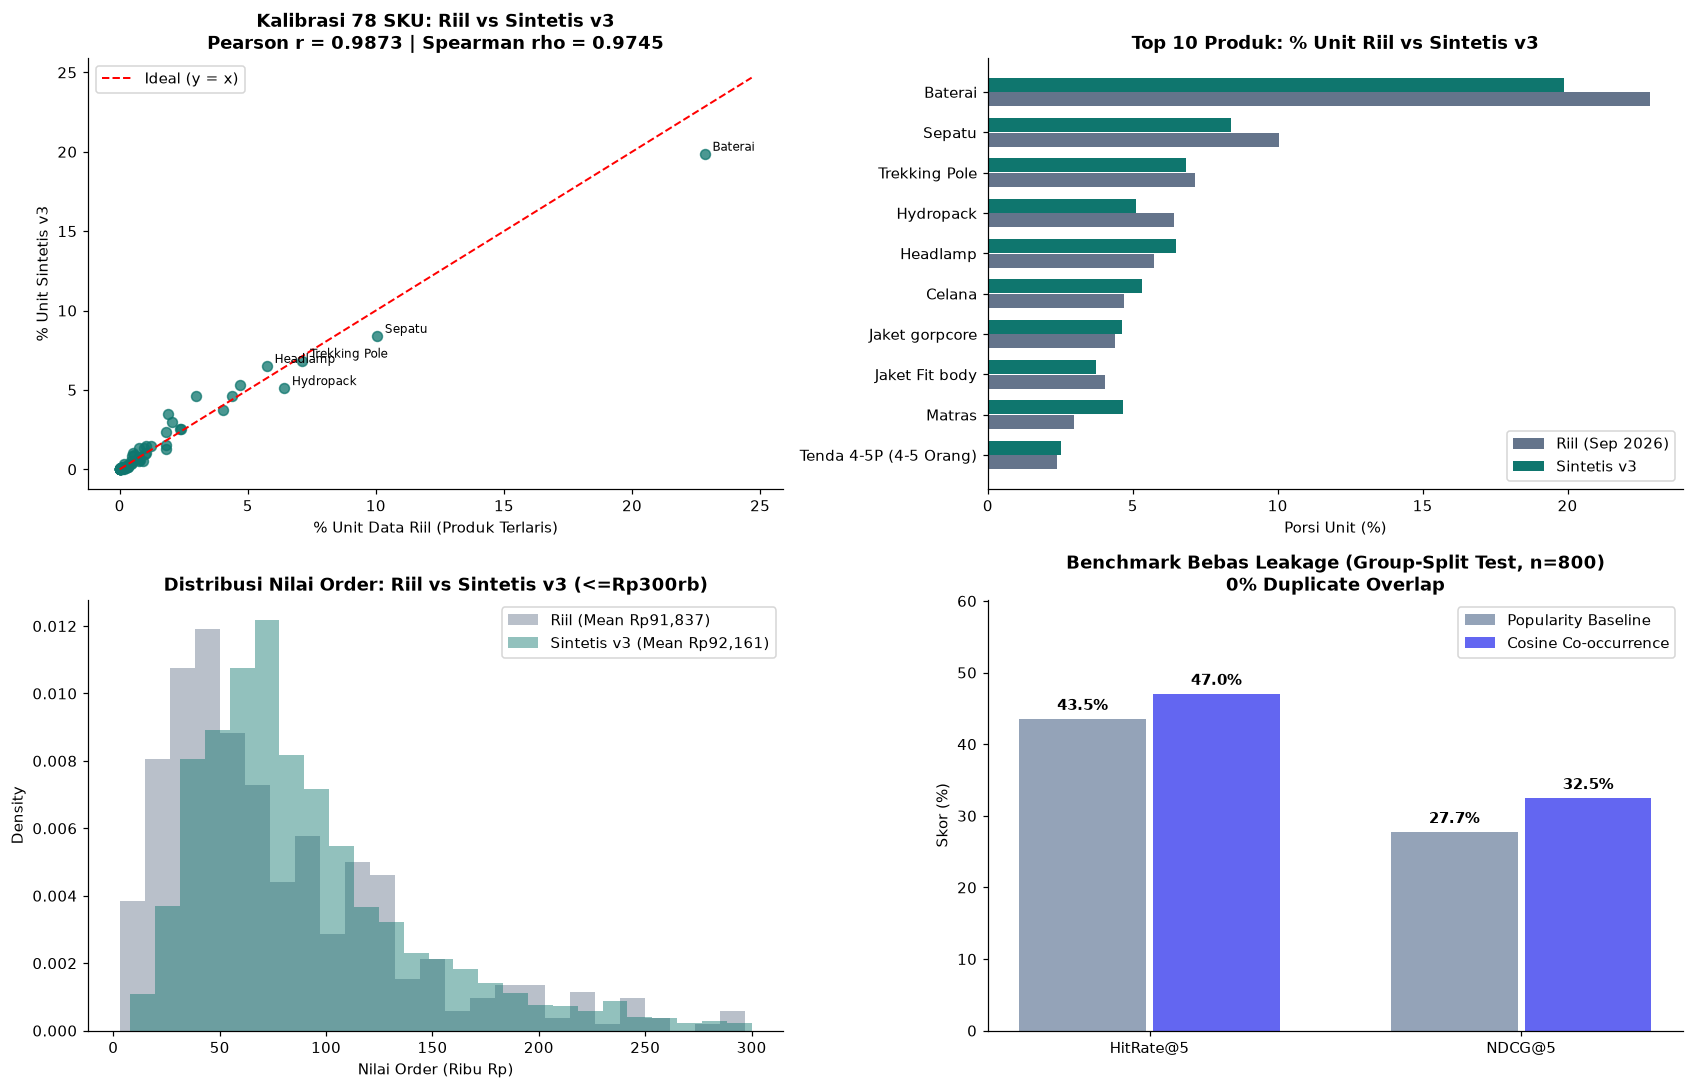

In [16]:
# Dashboard Validasi 2x2: Kualitas Kalibrasi v3 & Benchmark Bebas Leakage
syn_units_s = df_order_details_v3.groupby("product_id")["quantity"].sum()
tot_syn_u_v = syn_units_s.sum()
tot_real_u_v = sum(real_qty.values())
all_pids_v = sorted(catalog_lookup.keys())

df_cmp = pd.DataFrame({
    "product_id": all_pids_v,
    "product_name": [catalog_lookup[p]["product_name_clean"] for p in all_pids_v],
    "real_pct": [100 * real_qty.get(p, 0.0) / tot_real_u_v for p in all_pids_v],
    "syn_pct": [100 * syn_units_s.get(p, 0) / tot_syn_u_v for p in all_pids_v],
})
r_val = float(df_cmp["real_pct"].corr(df_cmp["syn_pct"]))
rho_val = float(df_cmp["real_pct"].rank().corr(df_cmp["syn_pct"].rank()))

fig, axes = plt.subplots(2, 2, figsize=(15.5, 10))

# Panel A: Scatter % Unit Riil vs Sintetis v3 (78 SKU)
axes[0, 0].scatter(df_cmp["real_pct"], df_cmp["syn_pct"], color="#0F766E", alpha=0.75, s=42)
lim_max = max(df_cmp["real_pct"].max(), df_cmp["syn_pct"].max()) * 1.08
axes[0, 0].plot([0, lim_max], [0, lim_max], "r--", linewidth=1.3, label="Ideal (y = x)")
for _, row in df_cmp.nlargest(5, "real_pct").iterrows():
    axes[0, 0].annotate(row["product_name"], (row["real_pct"], row["syn_pct"]), xytext=(5, 2), textcoords="offset points", fontsize=8)
axes[0, 0].set_title(f"Kalibrasi 78 SKU: Riil vs Sintetis v3\nPearson r = {r_val:.4f} | Spearman rho = {rho_val:.4f}", fontweight="bold")
axes[0, 0].set_xlabel("% Unit Data Riil (Produk Terlaris)")
axes[0, 0].set_ylabel("% Unit Sintetis v3")
axes[0, 0].legend()

# Panel B: Top 10 Produk — Perbandingan % Unit Riil vs Sintetis v3
top10_c = df_cmp.nlargest(10, "real_pct").iloc[::-1]
y_pos = np.arange(len(top10_c))
axes[0, 1].barh(y_pos - 0.18, top10_c["real_pct"], height=0.35, label="Riil (Sep 2026)", color="#64748B")
axes[0, 1].barh(y_pos + 0.18, top10_c["syn_pct"], height=0.35, label="Sintetis v3", color="#0F766E")
axes[0, 1].set_yticks(y_pos)
axes[0, 1].set_yticklabels(top10_c["product_name"])
axes[0, 1].set_xlabel("Porsi Unit (%)")
axes[0, 1].set_title("Top 10 Produk: % Unit Riil vs Sintetis v3", fontweight="bold")
axes[0, 1].legend()

# Panel C: Overlay Distribusi Nilai Order (Riil vs Sintetis v3)
real_t_clip = df_orders_returned["total"][df_orders_returned["total"] <= 300000] / 1e3
syn_t_clip = df_transactions_v3["order_total"][df_transactions_v3["order_total"] <= 300000] / 1e3
axes[1, 0].hist(real_t_clip, bins=25, density=True, alpha=0.45, color="#64748B", label=f"Riil (Mean Rp{df_orders_returned['total'].mean():,.0f})")
axes[1, 0].hist(syn_t_clip, bins=25, density=True, alpha=0.45, color="#0F766E", label=f"Sintetis v3 (Mean Rp{df_transactions_v3['order_total'].mean():,.0f})")
axes[1, 0].set_title("Distribusi Nilai Order: Riil vs Sintetis v3 (<=Rp300rb)", fontweight="bold")
axes[1, 0].set_xlabel("Nilai Order (Ribu Rp)")
axes[1, 0].set_ylabel("Density")
axes[1, 0].legend()

# Panel D: Benchmark Bebas Leakage (Group-Split Test Set)
metrics_lbl = ["HitRate@5", "NDCG@5"]
pop_scores = [100 * pop_hits / n_eval, 100 * pop_ndcg / n_eval]
cooc_scores = [100 * cooc_hits / n_eval, 100 * cooc_ndcg / n_eval]
xm = np.arange(len(metrics_lbl))
bm1 = axes[1, 1].bar(xm - 0.18, pop_scores, width=0.34, label="Popularity Baseline", color="#94A3B8")
bm2 = axes[1, 1].bar(xm + 0.18, cooc_scores, width=0.34, label="Cosine Co-occurrence", color="#6366F1")
for b in list(bm1) + list(bm2):
    h = b.get_height()
    axes[1, 1].text(b.get_x() + b.get_width()/2, h + 0.8, f"{h:.1f}%", ha="center", va="bottom", fontsize=9.5, fontweight="bold")
axes[1, 1].set_xticks(xm)
axes[1, 1].set_xticklabels(metrics_lbl)
axes[1, 1].set_ylabel("Skor (%)")
axes[1, 1].set_ylim(0, max(cooc_scores) * 1.28)
axes[1, 1].set_title(f"Benchmark Bebas Leakage (Group-Split Test, n={n_eval})\n0% Duplicate Overlap", fontweight="bold")
axes[1, 1].legend()

plt.tight_layout()
plt.show()


## 7. Ekspor Excel v3 & Long-Format CSV Siap Pipeline Model


In [15]:
syn_units = df_order_details_v3.groupby("product_id")["quantity"].sum()
syn_baskets = df_order_details_v3.groupby("product_id")["transaction_id"].nunique()
tot_syn_u, tot_real_u = syn_units.sum(), sum(real_qty.values())
all_pids = sorted(catalog_lookup.keys())

r_vec = np.array([real_qty.get(p, 0.0) / tot_real_u for p in all_pids])
s_vec = np.array([syn_units.get(p, 0) / tot_syn_u for p in all_pids])
pearson_r = float(np.corrcoef(r_vec, s_vec)[0, 1])
spearman_rho = float(pd.Series(r_vec).rank().corr(pd.Series(s_vec).rank()))

df_val = pd.DataFrame([
    {"section": "UNIQUENESS", "metric": "Unique Combos TOTAL (%)", "synthetic_v3": round(100 * combo_series.nunique() / len(combo_series), 2), "real_sewascale": np.nan},
    {"section": "ANTI_LEAKAGE", "metric": "Group-Split Overlap (%)", "synthetic_v3": 0.0, "real_sewascale": 0.0},
    {"section": "ANTI_LEAKAGE", "metric": "Baskets size == 1", "synthetic_v3": 0, "real_sewascale": 0},
    {"section": "SUMMARY", "metric": "SKU Unit-Share Pearson r", "synthetic_v3": round(pearson_r, 4), "real_sewascale": 1.0},
    {"section": "SUMMARY", "metric": "SKU Unit-Share Spearman rho", "synthetic_v3": round(spearman_rho, 4), "real_sewascale": 1.0},
    {"section": "SUMMARY", "metric": "Order Total Mean (Rp)", "synthetic_v3": round(df_transactions_v3["order_total"].mean()), "real_sewascale": round(df_orders_returned["total"].mean())},
    {"section": "SUMMARY", "metric": "Order Total Median (Rp)", "synthetic_v3": round(df_transactions_v3["order_total"].median()), "real_sewascale": round(df_orders_returned["total"].median())},
])

df_product_ref_v3 = df_catalog_clean.copy()
df_product_ref_v3["real_qty_sep2026"] = df_product_ref_v3["product_id"].map(lambda p: round(real_qty.get(p, 0.0), 1))
df_product_ref_v3["syn_units_v3"] = df_product_ref_v3["product_id"].map(lambda p: int(syn_units.get(p, 0)))
df_product_ref_v3["syn_baskets_v3"] = df_product_ref_v3["product_id"].map(lambda p: int(syn_baskets.get(p, 0)))

EXPORT_FILES = False  # Ubah ke True jika ingin mengekspor/menimpa ulang Excel & CSV (pastikan Excel ditutup dulu)
OUT_XLSX = "Synthetic_Basket_Dataset_4000_v3.xlsx"
OUT_CSV = "synthetic_order_details_v3.csv"

if EXPORT_FILES:
    with pd.ExcelWriter(OUT_XLSX, engine="openpyxl") as writer:
        df_transactions_v3.to_excel(writer, sheet_name="Transactions", index=False)
        df_order_details_v3.to_excel(writer, sheet_name="Order_Details", index=False)
        df_daily_rates.to_excel(writer, sheet_name="Daily_Rates", index=False)
        orders_clean.to_excel(writer, sheet_name="Orders_Clean_Real", index=False)
        df_val.to_excel(writer, sheet_name="Validation_Syn_vs_Real", index=False)
        df_product_ref_v3.to_excel(writer, sheet_name="Product_Reference", index=False)
    df_order_details_v3.to_csv(OUT_CSV, index=False)
    print(f"Selesai! Ekspor: {OUT_XLSX} & {OUT_CSV} (Pearson={pearson_r:.4f}, Spearman={spearman_rho:.4f})")
else:
    print(f"Validasi selesai (EXPORT_FILES=False, file eksisting tidak ditimpa). Pearson={pearson_r:.4f}, Spearman={spearman_rho:.4f}")


Validasi selesai (EXPORT_FILES=False, file eksisting tidak ditimpa). Pearson=0.9873, Spearman=0.9745
